# 17 - Text Features and Popularity

Explore how title and text-derived features relate to movie popularity.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

PROJECT_ROOT = Path.cwd().parent.parent
df = pd.read_csv(PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv")

plt.style.use("seaborn-v0_8-whitegrid")


Matplotlib is building the font cache; this may take a moment.


## Log Popularity by Title Difference

Compare the popularity distributions for movies whose title matches the original title and those whose title differs.

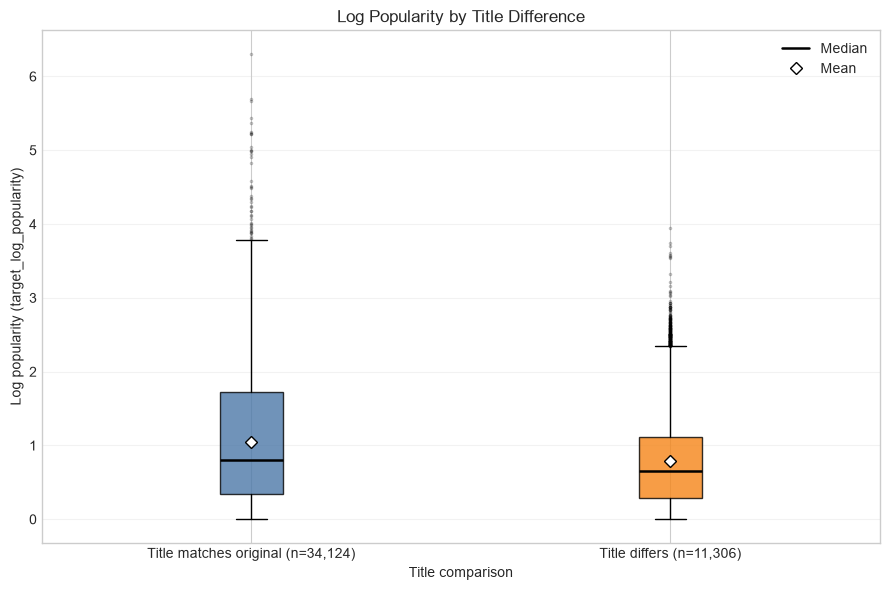

In [2]:
from matplotlib.lines import Line2D

plot_data = df[["title_differs_from_original", "target_log_popularity"]].dropna()
group_order = [0, 1]
groups = [
    plot_data.loc[plot_data["title_differs_from_original"] == value, "target_log_popularity"]
    for value in group_order
]
group_labels = [
    f"Title matches original (n={len(groups[0]):,})",
    f"Title differs (n={len(groups[1]):,})",
]

fig, ax = plt.subplots(figsize=(9, 6))
boxplot = ax.boxplot(
    groups,
    positions=[1, 2],
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6},
    medianprops={"color": "black", "linewidth": 1.8},
    flierprops={"marker": ".", "markersize": 3, "alpha": 0.25},
)
for box, color in zip(boxplot["boxes"], ["#4C78A8", "#F58518"]):
    box.set_facecolor(color)
    box.set_alpha(0.8)

ax.set_xticks([1, 2], group_labels)
ax.set_title("Log Popularity by Title Difference")
ax.set_xlabel("Title comparison")
ax.set_ylabel("Log popularity (target_log_popularity)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    handles=[
        Line2D([0], [0], color="black", linewidth=1.8, label="Median"),
        Line2D([0], [0], marker="D", color="black", markerfacecolor="white", linestyle="None", label="Mean"),
    ],
    frameon=False,
)
fig.tight_layout()
plt.show()

**Insight:** The median log popularity is lower for movies with a different title (0.65) than for movies whose title matches the original (0.81). This is an unadjusted association, not evidence that changing a title causes lower popularity.

## Correlation Heatmap: Text Features and Popularity

Pearson correlations show the direction and strength of each pairwise linear association.

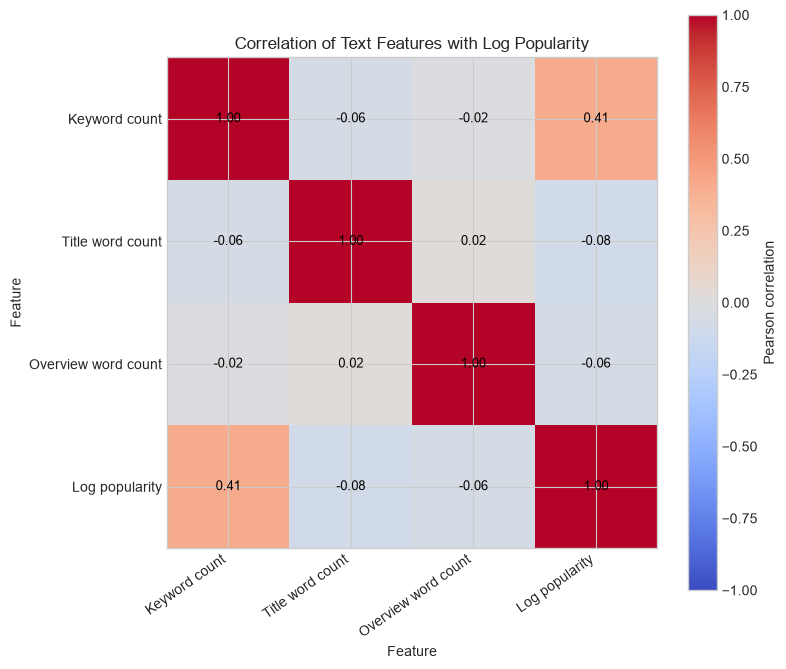

In [4]:
feature_columns = [
    "keyword_count",
    "title_word_count",
    "overview_word_count",
    "target_log_popularity",
]
feature_labels = [
    "Keyword count",
    "Title word count",
    "Overview word count",
    "Log popularity",
]
corr = df[feature_columns].corr()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="equal")
ax.set_xticks(np.arange(len(feature_labels)), feature_labels, rotation=35, ha="right")
ax.set_yticks(np.arange(len(feature_labels)), feature_labels)
for row in range(len(feature_labels)):
    for column in range(len(feature_labels)):
        value = corr.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color="black", fontsize=9)
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.set_title("Correlation of Text Features with Log Popularity")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

**Insight:** Keyword count has the strongest correlation with log popularity among these text features (r = 0.41). Title and overview word counts have weak negative correlations; these relationships are descriptive, not causal.